# 03 · XGBoost con SHAP

La regresión de `03_regresion_por_edicion` supone que la nota sube en línea recta con el compromiso y con los recursos de estudio, y que los perfiles solo se diferencian por su pendiente. Este notebook usa XGBoost (árboles de decisión potenciados), que no supone ninguna forma, sobre los mismos alumnos y variables, y SHAP para leer lo que ha aprendido:

* ¿Predice la nota mejor que la regresión? Si no, la forma lineal no deja fuera nada importante (sección 2).
* ¿Cuánto pesa cada variable en la predicción, y ha cambiado de 2012 a 2022? (sección 3)
* ¿Qué forma tiene la relación del compromiso y de los recursos de estudio con la nota? En particular, si la de los recursos se aplana cerca del techo de seis (sección 4).
* ¿Coinciden las pendientes por perfil con las de la regresión? (sección 5)

**Cómo se hace.**
* **Un modelo por edición y valor plausible.** Las variables son las de la regresión en sus unidades originales y con sus huecos (`matriz_xgboost`, `src/preparacion_modelo.py`): las dos de interés, los controles, el perfil y el país como variables categóricas. El país hace el papel del efecto fijo, pero los árboles pueden combinarlo con otras variables. Se pondera con `SENWT`.
* **Profundidad y número de árboles por validación cruzada.** Los pliegues se separan por centro, para que ningún centro esté a la vez en el entrenamiento y en la prueba (sección 1).
* **Un valor SHAP por alumno y variable.** Es cuántos puntos suma o resta esa variable a su predicción frente a la media. Se calcula con el algoritmo exacto para árboles de XGBoost y se promedia entre los modelos de los valores plausibles.

**Qué no dice.** Como la regresión, describe asociaciones, no efectos causales. Además, un valor SHAP reparte entre las variables lo que el modelo predice, así que dos variables correlacionadas (por ejemplo, los recursos de estudio y el origen social) se reparten el mérito de una forma que depende del modelo.

## 0. Configuración

In [1]:
import os
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import Markdown, display
from sklearn.model_selection import GroupKFold

sys.path.append(os.path.abspath('../../'))   # para importar `src`
from src.modelo_regresion import matriz_diseno
from src.preparacion_modelo import CONTROLES, DE_INTERES, matriz_regresion, matriz_xgboost

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)

EDICIONES = [2012, 2015, 2018, 2022]
RUTA_PROCESADOS = '../../data/processed'
RUTA_MODELOS = '../../models'
RUTA_REPORTS = '../../reports'
VARIABLES = DE_INTERES + CONTROLES + ['perfil_categoria', 'pais_categoria']
NOMBRES = {'Indice_Compromiso_Competencia': 'compromiso', 'recursos_estudio': 'recursos de estudio', 'HISEI_TREND': 'ocupación de los padres',
           'PAREDINT_TREND': 'estudios de los padres', 'riqueza_hogar': 'riqueza del hogar', 'cantidad_libros': 'libros en casa', 'sexo_femenino': 'sexo (chica)',
           'inmigrante': 'inmigrante', 'composicion_social_centro': 'composición social del centro', 'dotacion_centro': 'dotación del centro',
           'perfil_categoria': 'perfil del centro', 'pais_categoria': 'país'}
COLORES_EDICION = dict(zip(EDICIONES, plt.cm.Blues(np.linspace(0.4, 0.95, len(EDICIONES)))))
PARAMETROS_BASE = {'objective': 'reg:squarederror', 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'tree_method': 'hist',
                   'max_cat_to_onehot': 1, 'seed': 42}
PLIEGUES = 5

tabla = pd.read_parquet(os.path.join(RUTA_PROCESADOS, 'tabla_modelo_alumno.parquet'))
parametros = pd.read_parquet(os.path.join(RUTA_PROCESADOS, 'parametros_escala.parquet'))
# Mismos alumnos que la regresión: en unidades originales y con huecos para XGBoost, tipificados para la regresión
matriz_arboles = matriz_xgboost(tabla)
matriz_lineal = matriz_regresion(tabla, parametros)
assert (matriz_arboles[['CNTSTUID', 'centro']].to_numpy() == matriz_lineal[['CNTSTUID', 'centro']].to_numpy()).all()   # mismas filas, mismo orden


def valores_plausibles(datos):
    """Valores plausibles de matemáticas que tienen todas las filas de `datos` (5 en 2012, 10 en las demás)."""
    return [columna for columna in datos.columns if re.fullmatch(r'PV\d+MATH', columna) and datos[columna].notna().all()]


def r2_ponderado(observado, predicho, pesos):
    """Parte de la varianza ponderada de `observado` que explica `predicho`."""
    media = np.average(observado, weights=pesos)
    return 1 - np.average((observado - predicho) ** 2, weights=pesos) / np.average((observado - media) ** 2, weights=pesos)


def rmse_ponderado(observado, predicho, pesos):
    """Raíz del error cuadrático medio ponderado, en puntos de la nota."""
    return np.sqrt(np.average((observado - predicho) ** 2, weights=pesos))


def mae_ponderado(observado, predicho, pesos):
    """Error absoluto medio ponderado, en puntos de la nota."""
    return np.average(np.abs(observado - predicho), weights=pesos)


def datos_edicion(matriz, edicion):
    """Filas de `matriz` de `edicion`, con índice de 0 a n − 1."""
    return matriz[matriz['year'] == edicion].reset_index(drop=True)


def pliegues_por_centro(datos):
    """Índices de entrenamiento y prueba de `PLIEGUES` pliegues sin centros compartidos."""
    return list(GroupKFold(PLIEGUES).split(datos, groups=datos['centro']))


print(f"{len(matriz_arboles)} alumnos; variables: {VARIABLES}")
print('Huecos por variable (alumnos):', matriz_arboles[VARIABLES].isna().sum()[lambda huecos: huecos > 0].to_dict())

298782 alumnos; variables: ['Indice_Compromiso_Competencia', 'recursos_estudio', 'HISEI_TREND', 'PAREDINT_TREND', 'riqueza_hogar', 'cantidad_libros', 'sexo_femenino', 'inmigrante', 'composicion_social_centro', 'dotacion_centro', 'perfil_categoria', 'pais_categoria']
Huecos por variable (alumnos): {'HISEI_TREND': 11714, 'PAREDINT_TREND': 4712, 'riqueza_hogar': 5683, 'cantidad_libros': 996, 'sexo_femenino': 15, 'inmigrante': 4434, 'dotacion_centro': 20043}


## 1. Profundidad y número de árboles

Con el primer valor plausible de cada edición, se prueba la profundidad de los árboles (2, 4 o 6 niveles: cuantos más, más interacciones entre variables puede recoger). Para cada una se añaden árboles hasta que la predicción de los pliegues de prueba deja de mejorar en 50 rondas seguidas. Se elige la combinación con menor error en los pliegues de prueba. El R² se calcula a partir de ese error y de la varianza de la nota en la edición, así que es aproximado.

In [2]:
# Profundidad y número de árboles por validación cruzada con pliegues por centro y parada temprana (con el primer valor plausible)
PROFUNDIDADES = [2, 4, 6]
filas = []
for edicion in EDICIONES:
    datos = datos_edicion(matriz_arboles, edicion)
    matriz_dmatrix = xgb.DMatrix(datos[VARIABLES], label=datos['PV1MATH'], weight=datos['SENWT'], enable_categorical=True)
    varianza = np.cov(datos['PV1MATH'], aweights=datos['SENWT'])
    for profundidad in PROFUNDIDADES:
        validacion = xgb.cv({**PARAMETROS_BASE, 'max_depth': profundidad}, matriz_dmatrix, num_boost_round=3000, folds=pliegues_por_centro(datos),
                            early_stopping_rounds=50, metrics='rmse')
        error = validacion['test-rmse-mean'].iloc[-1]
        filas.append({'year': edicion, 'max_depth': profundidad, 'arboles': len(validacion), 'rmse_prueba': error, 'r2_aproximado': 1 - error ** 2 / varianza})
ajuste = pd.DataFrame(filas)
display(ajuste.round(3).set_index(['year', 'max_depth']))
# Por edición, la profundidad con menor error de prueba
elegidos = ajuste.loc[ajuste.groupby('year')['rmse_prueba'].idxmin()].set_index('year')
print('Elegidos por edición:')
print(elegidos[['max_depth', 'arboles']])

arboles  rmse_prueba  r2_aproximado
year max_depth                                     
2012 2             1305       73.881          0.385
     4              339       73.735          0.387
     6              135       73.966          0.384
2015 2             1136       75.905          0.309
     4              387       75.777          0.311
     6              150       75.890          0.309
2018 2             1106       75.682          0.312
     4              331       75.661          0.313
     6              175       75.881          0.309
2022 2             1015       75.260          0.331
     4              369       75.048          0.334
     6              159       75.030          0.335

Elegidos por edición:
      max_depth  arboles
year                    
2012          4      339
2015          4      387
2018          4      331
2022          6      159


**Qué se ve.**

* **La profundidad apenas importa.** En cada edición, las tres profundidades dan casi el mismo error de prueba (entre 73,7 y 76,0 puntos) y el mismo R² aproximado. En 2012, por ejemplo, va de 0,384 a 0,387.
* **Se eligen 4 niveles en 2012, 2015 y 2018, y 6 en 2022**, con entre 159 y 387 árboles.
* **Que haya poca diferencia es ya un indicio**: los árboles con más interacciones casi no ganan a los de dos niveles, que solo combinan dos variables.

## 2. ¿Predice mejor que la regresión?

Con los mismos pliegues por centro, se predice la nota de los alumnos de prueba con XGBoost (los parámetros elegidos) y con la regresión de `03_regresion_por_edicion` (pendiente por perfil, efecto fijo de país, controles con sus indicadores de «sin dato»; mínimos cuadrados ponderados). Se repite con cada valor plausible y se promedian las métricas de prueba, ponderadas con `SENWT`: el R², la raíz del error cuadrático medio (RMSE) y el error absoluto medio (MAE), los dos en puntos de matemáticas. Si XGBoost apenas mejora a la regresión, las no linealidades y las interacciones que puede captar pesan poco.

In [3]:
# Predicción fuera de muestra de XGBoost y de la regresión con los mismos pliegues, para cada valor plausible
filas = []
for edicion in EDICIONES:
    arboles, lineal = datos_edicion(matriz_arboles, edicion), datos_edicion(matriz_lineal, edicion)
    diseno = matriz_diseno(lineal, por_perfil=True).to_numpy(dtype=float)
    pesos = arboles['SENWT'].to_numpy()
    pliegues = pliegues_por_centro(arboles)
    parametros_xgb = {**PARAMETROS_BASE, 'max_depth': int(elegidos.loc[edicion, 'max_depth'])}
    for valor_plausible in valores_plausibles(arboles):
        nota = arboles[valor_plausible].to_numpy()
        prediccion_xgb, prediccion_lineal = np.zeros(len(nota)), np.zeros(len(nota))
        for entrenamiento, prueba in pliegues:
            modelo = xgb.train(parametros_xgb, xgb.DMatrix(arboles.loc[entrenamiento, VARIABLES], label=nota[entrenamiento], weight=pesos[entrenamiento],
                                                           enable_categorical=True), num_boost_round=int(elegidos.loc[edicion, 'arboles']))
            prediccion_xgb[prueba] = modelo.predict(xgb.DMatrix(arboles.loc[prueba, VARIABLES], enable_categorical=True))
            # Regresión ponderada: mínimos cuadrados con filas multiplicadas por la raíz del peso
            raiz = np.sqrt(pesos[entrenamiento])[:, None]
            coeficientes = np.linalg.lstsq(diseno[entrenamiento] * raiz, nota[entrenamiento] * raiz[:, 0], rcond=None)[0]
            prediccion_lineal[prueba] = diseno[prueba] @ coeficientes
        for modelo_nombre, prediccion in (('regresion', prediccion_lineal), ('xgboost', prediccion_xgb)):
            filas.append({'edicion': edicion, 'modelo': modelo_nombre, 'valor_plausible': valor_plausible, 'r2': r2_ponderado(nota, prediccion, pesos),
                          'rmse': rmse_ponderado(nota, prediccion, pesos), 'mae': mae_ponderado(nota, prediccion, pesos), 'n_alumnos': len(nota)})
por_valor_plausible = pd.DataFrame(filas)
# R², RMSE y MAE medios entre valores plausibles
comparacion = por_valor_plausible.pivot_table(index='edicion', columns='modelo', values='r2', aggfunc=['mean', 'min', 'max']).swaplevel(axis=1).sort_index(axis=1)
comparacion[('diferencia', 'mean')] = comparacion[('xgboost', 'mean')] - comparacion[('regresion', 'mean')]
display(Markdown('**R² de prueba (media, mínimo y máximo entre valores plausibles)**'))
display(comparacion.round(4))
metricas = (por_valor_plausible.groupby(['edicion', 'modelo'])
            .agg(r2=('r2', 'mean'), rmse=('rmse', 'mean'), mae=('mae', 'mean'), n_alumnos=('n_alumnos', 'first'), valores_plausibles=('valor_plausible', 'size'))
            .reset_index().assign(conjunto='validacion_cruzada'))
metricas = metricas[['edicion', 'modelo', 'conjunto', 'r2', 'rmse', 'mae', 'n_alumnos', 'valores_plausibles']]
display(Markdown('**RMSE y MAE de prueba (puntos de matemáticas, media entre valores plausibles)**'))
display(metricas.pivot(index='edicion', columns='modelo', values=['rmse', 'mae']).round(2))

**R² de prueba (media, mínimo y máximo entre valores plausibles)**

modelo  regresion                 xgboost                 diferencia
              max    mean     min     max    mean     min       mean
edicion                                                             
2012       0.3550  0.3540  0.3525  0.3879  0.3852  0.3832     0.0312
2015       0.2819  0.2791  0.2767  0.3141  0.3112  0.3076     0.0321
2018       0.2951  0.2923  0.2879  0.3204  0.3170  0.3128     0.0247
2022       0.3142  0.3117  0.3089  0.3382  0.3356  0.3323     0.0239

**RMSE y MAE de prueba (puntos de matemáticas, media entre valores plausibles)**

rmse               mae        
modelo  regresion xgboost regresion xgboost
edicion                                    
2012        75.75   73.90     60.30   58.73
2015        77.27   75.54     61.51   60.05
2018        77.21   75.85     61.28   60.21
2022        76.16   74.83     60.54   59.48

**Qué se ve.**

* **XGBoost predice algo mejor que la regresión en todas las ediciones**, entre 0,024 y 0,032 puntos más de R². Por ejemplo, 0,385 frente a 0,354 en 2012 y 0,336 frente a 0,312 en 2022.
* **La mejora es pequeña frente a lo que ninguno de los dos explica.** Ambos dejan sin explicar dos tercios de la varianza de la nota, que depende de mucho más que estas variables.
* **Para un alumno concreto, los dos modelos se equivocan mucho.** El error absoluto medio de prueba es de 58,73 a 60,21 puntos con XGBoost y de 60,30 a 61,51 con la regresión. El RMSE es de 73,90 a 75,85 y de 75,75 a 77,27 puntos. XGBoost los reduce en menos de 2 puntos. Los modelos sirven para describir relaciones medias, no para predecir la nota de un alumno.
* **Lo que la regresión deja fuera por suponer rectas e interacciones solo con el perfil pesa poco.** Las secciones siguientes muestran de dónde sale esa pequeña mejora.

## 3. Cuánto pesa cada variable

Con los parámetros elegidos, se entrena un modelo por edición y valor plausible con todos los alumnos y se calculan los valores SHAP de cada alumno, promediados entre valores plausibles. La importancia de una variable es la media (con `SENWT`) del valor absoluto de su SHAP: cuántos puntos mueve, de media, la predicción de un alumno. Sirve para comparar ediciones; no es un efecto, porque las variables correlacionadas se reparten el mérito.

**Media del valor absoluto de SHAP (puntos de matemáticas)**

year,2012,2015,2018,2022
composición social del centro,25.95,18.50,21.07,21.72
país,15.93,14.08,14.50,15.15
libros en casa,17.28,17.64,15.21,14.29
sexo (chica),7.85,8.05,7.62,9.58
compromiso,9.56,8.57,10.04,9.50
ocupación de los padres,7.94,8.69,7.89,7.84
dotación del centro,3.50,3.38,3.77,3.46
perfil del centro,3.36,2.50,2.17,3.08
recursos de estudio,2.75,3.07,2.88,3.01
riqueza del hogar,1.58,2.04,3.03,2.22


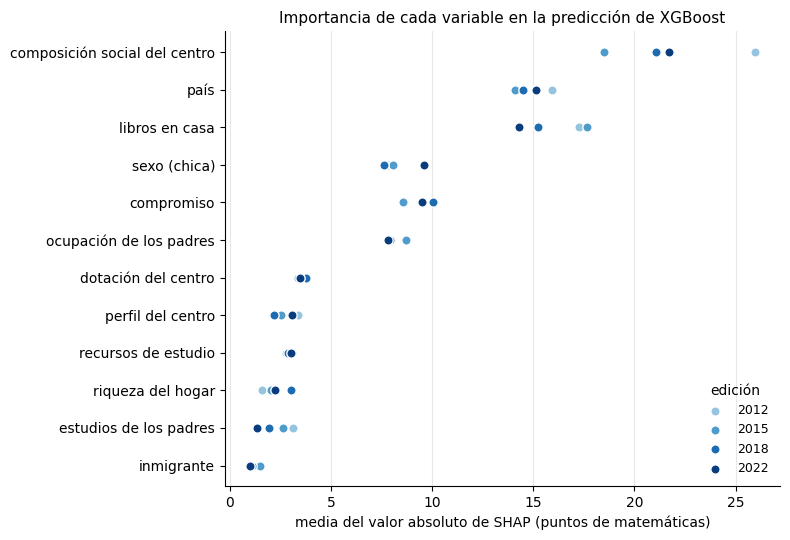

In [4]:
# SHAP de cada alumno: un modelo por valor plausible con todos los datos, y la media de sus contribuciones
tablas_shap = []
for edicion in EDICIONES:
    datos = datos_edicion(matriz_arboles, edicion)
    todos = xgb.DMatrix(datos[VARIABLES], enable_categorical=True)
    parametros_xgb = {**PARAMETROS_BASE, 'max_depth': int(elegidos.loc[edicion, 'max_depth'])}
    suma, suma_prediccion = 0, 0
    for valor_plausible in valores_plausibles(datos):
        modelo = xgb.train(parametros_xgb, xgb.DMatrix(datos[VARIABLES], label=datos[valor_plausible], weight=datos['SENWT'], enable_categorical=True),
                           num_boost_round=int(elegidos.loc[edicion, 'arboles']))
        suma = suma + modelo.predict(todos, pred_contribs=True)
        suma_prediccion = suma_prediccion + modelo.predict(todos)
    contribuciones = suma / len(valores_plausibles(datos))
    shap_edicion = pd.DataFrame(contribuciones[:, :-1], columns=VARIABLES).assign(base=contribuciones[:, -1],
                                                                                  prediccion=suma_prediccion / len(valores_plausibles(datos)))
    tablas_shap.append(pd.concat([datos[['CNT', 'CNTSCHID', 'CNTSTUID', 'year', 'perfil', 'SENWT']], shap_edicion], axis=1))
shap_alumno = pd.concat(tablas_shap, ignore_index=True)

# Importancia: media ponderada del valor absoluto de SHAP
importancia = (shap_alumno.groupby('year').apply(lambda grupo: pd.Series({variable: np.average(grupo[variable].abs(), weights=grupo['SENWT']) for variable in VARIABLES}),
                                                 include_groups=False).T)
importancia = importancia.sort_values(2022, ascending=False)
importancia.index = importancia.index.map(NOMBRES)
display(Markdown('**Media del valor absoluto de SHAP (puntos de matemáticas)**'))
display(importancia.round(2))

# Figura: importancia por edición
fig, eje = plt.subplots(figsize=(8, 5.5))
posicion = np.arange(len(importancia))
for edicion in EDICIONES:
    eje.scatter(importancia[edicion], posicion, color=COLORES_EDICION[edicion], s=45, label=str(edicion), zorder=3, edgecolor='white', linewidth=1)
eje.set_yticks(posicion, importancia.index)
eje.invert_yaxis()
eje.set_xlabel('media del valor absoluto de SHAP (puntos de matemáticas)')
eje.grid(axis='x', alpha=0.3)
eje.spines[['top', 'right']].set_visible(False)
eje.legend(title='edición', fontsize=9, frameon=False, loc='lower right')
eje.set_title('Importancia de cada variable en la predicción de XGBoost', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/03_xgboost_importancia.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **El compromiso está entre las variables del alumno que más mueven la predicción**, tras los libros en casa y a la par del sexo: entre 8,57 y 10,04 puntos de media, sin tendencia entre ediciones.
* **Los recursos de estudio mueven unos 3 puntos** (de 2,75 a 3,07), estables. Pesan menos que el compromiso, como en la regresión.
* **Las variables que más mueven la predicción son la composición social del centro** (de 18,50 a 25,95), **el país** (de 14,08 a 15,93) **y los libros en casa** (de 14,29 a 17,64).
* **El perfil del centro mueve poco** (de 2,17 a 3,36) una vez conocida la composición social y el país.

## 4. La forma de la relación

Para cada valor del compromiso y de los recursos de estudio (redondeados al entero más cercano), la media de su valor SHAP: cuánto suma o resta a la predicción, frente a la media, tener ese valor. Se dejan fuera los valores con menos de 100 alumnos. La línea discontinua es lo que diría la regresión: la pendiente común de `03_regresion_por_edicion` en unidades originales (`models/coeficientes_regresion.csv`), centrada en la media. Si los puntos siguen la recta, la relación es lineal; si se doblan, no.

**Recursos de estudio: SHAP medio por número de recursos (puntos)**

year,2012,2015,2018,2022
valor,,,,
0.0,NaN,-31.9,NaN,NaN
1.0,-20.9,-28.7,-24.4,-24.4
2.0,-17.5,-18.7,-20.7,-24.5
3.0,-10.3,-15.3,-11.0,-14.5
4.0,-4.8,-5.5,-4.5,-6.0
5.0,-0.4,1.3,1.3,0.2
6.0,2.7,2.1,2.0,2.3


**Recursos de estudio: alumnos por número de recursos**

year,2012,2015,2018,2022
valor,,,,
0.0,0,106,0,0
1.0,203,230,159,119
2.0,667,746,782,803
3.0,2587,2704,3159,3624
4.0,9965,8382,10142,9939
5.0,24432,21370,21908,24262
6.0,35924,35257,33645,47503


**Compromiso: SHAP medio por valor del índice (puntos)**

year,2012,2015,2018,2022
valor,,,,
-2.10,-26.4,-22.5,-24.4,-23.4
-1.39,-18.2,-14.5,-16.0,-17.0
-1.00,-12.9,-6.8,-8.4,-10.7
-0.98,-19.3,-20.8,-15.9,-11.4
-0.68,-7.4,-1.1,-4.8,-5.2
-0.29,-5.4,1.1,0.9,-1.1
-0.27,-13.7,-11.5,-9.7,-2.4
0.12,-11.2,-4.7,-6.2,-0.9
0.41,9.1,9.8,10.9,8.7


**Compromiso: componentes de cada valor del índice** (media y desviación típica en las cuatro ediciones; desviación 0 = cada valor es una sola combinación)

deberes_en_u      SKIPPING      TARDYSD     
              mean  std     mean  std    mean  std
valor                                             
-2.10          0.0  0.0      1.0  0.0     2.0  0.0
-1.39          0.0  0.0      1.0  0.0     1.0  0.0
-1.00          0.0  0.0      0.0  0.0     2.0  0.0
-0.98          1.0  0.0      1.0  0.0     2.0  0.0
-0.68          0.0  0.0      1.0  0.0     0.0  0.0
-0.29          0.0  0.0      0.0  0.0     1.0  0.0
-0.27          1.0  0.0      1.0  0.0     1.0  0.0
 0.12          1.0  0.0      0.0  0.0     2.0  0.0
 0.41          0.0  0.0      0.0  0.0     0.0  0.0
 0.44          1.0  0.0      1.0  0.0     0.0  0.0
 0.83          1.0  0.0      0.0  0.0     1.0  0.0
 1.54          1.0  0.0      0.0  0.0     0.0  0.0

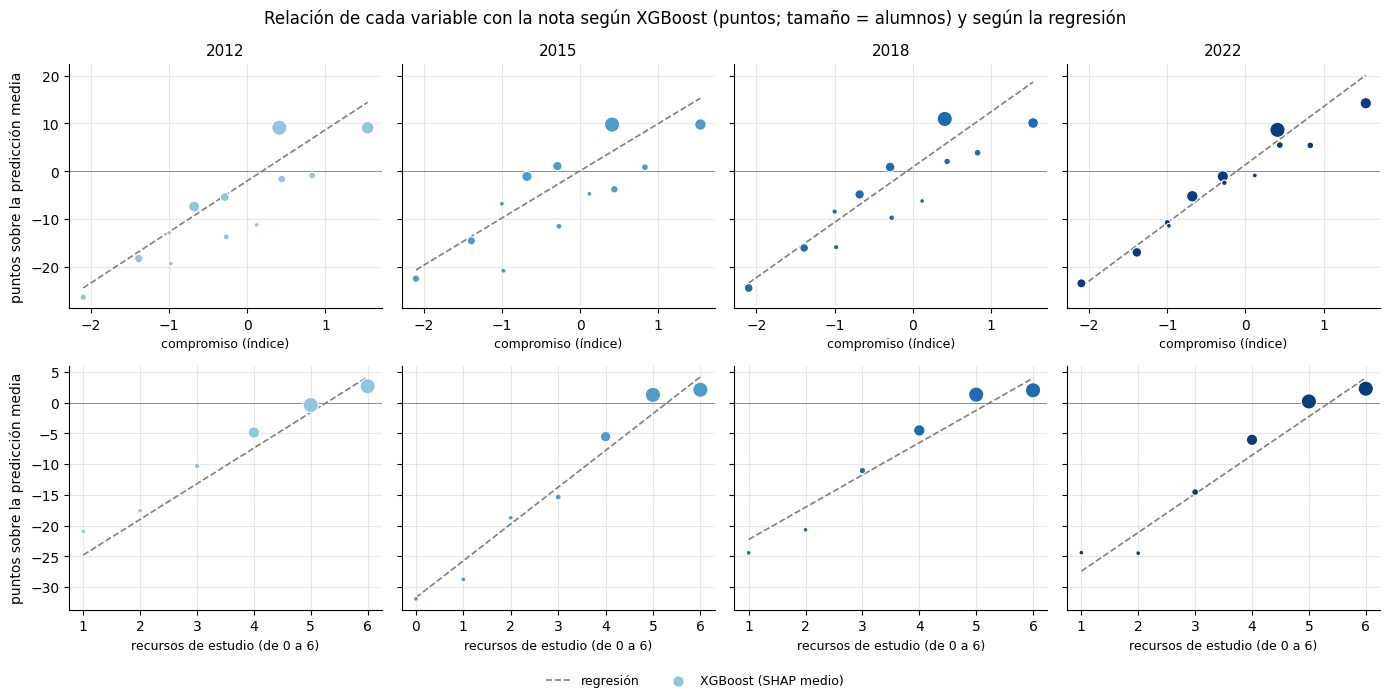

In [5]:
# Pendiente común de la regresión en unidades originales, para compararla con SHAP
coeficientes = pd.read_csv(os.path.join(RUTA_MODELOS, 'coeficientes_regresion.csv'))
resultados_regresion = (coeficientes[coeficientes['variable'].isin(DE_INTERES) & (coeficientes['unidad'] == 'original')]
                        .rename(columns={'edicion': 'year', 'coeficiente': 'puntos_por_unidad'}))
pendiente_comun = resultados_regresion[resultados_regresion['tipo'] == 'principal'].set_index(['variable', 'year'])['puntos_por_unidad']
valores = matriz_arboles[DE_INTERES]
# Valores agrupados: compromiso con dos decimales, recursos al entero más cercano
redondeados = {'Indice_Compromiso_Competencia': valores['Indice_Compromiso_Competencia'].round(2),
               'recursos_estudio': np.floor(valores['recursos_estudio'] + 0.5)}
forma = {}
for variable in DE_INTERES:
    agrupado = pd.DataFrame({'year': shap_alumno['year'], 'valor': redondeados[variable], 'shap': shap_alumno[variable], 'peso': shap_alumno['SENWT'],
                             'original': valores[variable]})
    # SHAP medio de cada valor con al menos 100 alumnos
    forma[variable] = agrupado.groupby(['year', 'valor']).apply(lambda grupo: pd.Series({
        'alumnos': len(grupo), 'shap_medio': np.average(grupo['shap'], weights=grupo['peso'])}), include_groups=False).query('alumnos >= 100')
    medias = agrupado.groupby('year').apply(lambda grupo: pd.Series({'valor_medio': np.average(grupo['original'], weights=grupo['peso']),
                                                                    'shap_medio': np.average(grupo['shap'], weights=grupo['peso'])}), include_groups=False)
    forma[variable] = forma[variable].join(medias, rsuffix='_edicion')
    # Recta de la regresión con la misma referencia que SHAP: pasa por la media de la edición
    forma[variable]['regresion'] = (pendiente_comun.xs(variable).reindex(forma[variable].index.get_level_values('year')).to_numpy()
                                    * (forma[variable].index.get_level_values('valor') - forma[variable]['valor_medio']) + forma[variable]['shap_medio_edicion'])
display(Markdown('**Recursos de estudio: SHAP medio por número de recursos (puntos)**'))
display(forma['recursos_estudio']['shap_medio'].unstack('year').round(1))
display(Markdown('**Recursos de estudio: alumnos por número de recursos**'))
display(forma['recursos_estudio']['alumnos'].unstack('year').fillna(0).astype(int))
display(Markdown('**Compromiso: SHAP medio por valor del índice (puntos)**'))
display(forma['Indice_Compromiso_Competencia']['shap_medio'].unstack('year').round(1))
# Qué combinación de componentes hay detrás de cada valor del índice
componentes = matriz_arboles.assign(valor=redondeados['Indice_Compromiso_Competencia']).groupby('valor')[['deberes_en_u', 'SKIPPING', 'TARDYSD']].agg(['mean', 'std'])
display(Markdown('**Compromiso: componentes de cada valor del índice** (media y desviación típica en las cuatro ediciones; desviación 0 = cada valor es una sola combinación)'))
display(componentes.round(2))

# Figura: SHAP medio por valor frente a la recta de la regresión
fig, ejes = plt.subplots(2, len(EDICIONES), figsize=(14, 7), sharey='row')
for fila, variable in enumerate(DE_INTERES):
    for columna, edicion in enumerate(EDICIONES):
        eje = ejes[fila, columna]
        puntos = forma[variable].xs(edicion, level='year')
        eje.plot(puntos.index, puntos['regresion'], color='grey', linestyle='--', linewidth=1.2, label='regresión')
        eje.scatter(puntos.index, puntos['shap_medio'], s=np.clip(puntos['alumnos'] / 150, 12, 120), color=COLORES_EDICION[edicion], zorder=3,
                    edgecolor='white', linewidth=0.8, label='XGBoost (SHAP medio)')
        eje.axhline(0, color='grey', linewidth=0.6)
        eje.grid(alpha=0.3)
        eje.spines[['top', 'right']].set_visible(False)
        if fila == 0:
            eje.set_title(str(edicion), fontsize=11)
        eje.set_xlabel(NOMBRES[variable] + (' (índice)' if fila == 0 else ' (de 0 a 6)'), fontsize=9)
    ejes[fila, 0].set_ylabel('puntos sobre la predicción media')
fig.legend(*ejes[0, 0].get_legend_handles_labels(), loc='lower center', ncol=2, fontsize=9, frameon=False)
fig.suptitle('Relación de cada variable con la nota según XGBoost (puntos; tamaño = alumnos) y según la regresión', fontsize=12)
plt.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(f'{RUTA_REPORTS}/03_xgboost_forma_relacion.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **Los recursos de estudio se aplanan cerca del techo, en todas las ediciones.**
  * De 3 a 4 recursos, el SHAP medio sube de −10,3 a −4,8 en 2012 y de −14,5 a −6,0 en 2022.
  * De 4 a 5, de −4,8 a −0,4 y de −6,0 a 0,2.
  * De 5 a 6, solo de −0,4 a 2,7 y de 0,2 a 2,3.
  * La regresión, con una recta, exagera lo que suma el sexto recurso y se queda corta en lo que resta tener solo 3 o 4 (gráfico).
  * La forma es la misma en las cuatro ediciones: el aplanamiento no cambia la conclusión de que la relación es estable.
* **El compromiso no se comporta como una escala ordenada.**
  * Cada uno de sus 12 valores es una sola combinación de deberes, absentismo e impuntualidad (tabla de componentes).
  * XGBoost no ordena los valores como el índice, porque el absentismo pesa mucho más que los deberes. El valor 0,41 (deberes fuera del tercil central, sin faltar ni llegar tarde) suma 9,1 puntos en 2012. El 0,44 (deberes en el tercil central, pero faltando a clase) resta 1,6.
  * El índice, con pesos iguales, ordena al revés esos dos casos.
* **Lo que cambia de 2012 a 2022 es el valor de los deberes.** A igual asistencia, estar en el tercil central de deberes se asocia a poca diferencia en 2012 y a mucha en 2022:
  * sin faltar ni llegar tarde, 9,1 frente a 9,1 en 2012 y 8,7 frente a 14,2 en 2022;
  * faltando y llegando tarde una o dos veces, −18,2 frente a −13,7 en 2012 y −17,0 frente a −2,4 en 2022.
  * Es lo mismo que mostraban los componentes en `03_robustez_regresion` (sección 2). La subida de la pendiente del compromiso viene de los deberes, el componente que peor se compara entre ediciones.

## 5. Pendientes por perfil

Dentro de cada perfil y edición, la pendiente de la recta (ponderada con `SENWT`) que mejor ajusta el SHAP de una variable frente a su valor: los puntos que XGBoost asocia a una unidad más en ese perfil. Se compara con la pendiente por perfil de la regresión en las mismas unidades (`puntos_por_unidad`), sin los perfiles-edición poco representativos. Los árboles tienden a dar pendientes algo más planas (aprenden despacio y cortan en escalones), así que importa más el orden de los perfiles que el nivel. Se señala el privado urbano grande en 2022 (`03_australia_privados_grandes`).

compromiso: correlación entre pendientes de XGBoost y de la regresión, 54 perfiles-edición: 0.59; por edición: {2012: 0.53, 2015: 0.67, 2018: 0.58, 2022: 0.82}
  mediana del cociente XGBoost / regresión: 0.90
recursos de estudio: correlación entre pendientes de XGBoost y de la regresión, 54 perfiles-edición: 0.46; por edición: {2012: 0.72, 2015: 0.4, 2018: 0.65, 2022: 0.42}
  mediana del cociente XGBoost / regresión: 0.75


**PRI_URB_MACRO: pendiente de XGBoost y de la regresión (puntos por unidad)**

pendiente_shap                    puntos_por_unidad                     
year                                    2012  2015  2018   2022              2012   2015   2018   2022
variable                                                                                              
Indice_Compromiso_Competencia           9.78  8.49  9.65  11.43             16.88  11.26  13.28  15.24
recursos_estudio                        3.84  3.96  2.52   4.99              3.61   6.90   2.80  18.79

**Recursos de estudio: pendiente de XGBoost por perfil y edición (puntos por recurso)**

year,2012,2015,2018,2022
perfil,,,,
CON_RUR_MACRO,4.63,3.84,4.26,5.35
CON_RUR_MED,3.66,3.98,4.11,4.97
CON_RUR_PEQ,4.23,4.60,3.83,5.33
CON_URB_MACRO,4.23,3.95,3.76,5.00
CON_URB_MED,4.06,4.69,4.04,5.07
CON_URB_PEQ,4.22,4.75,4.48,4.57
PRI_URB_MACRO,3.84,3.96,2.52,4.99
PRI_URB_MED,3.30,2.70,1.89,4.70
PRI_URB_PEQ,4.36,2.74,2.59,4.41


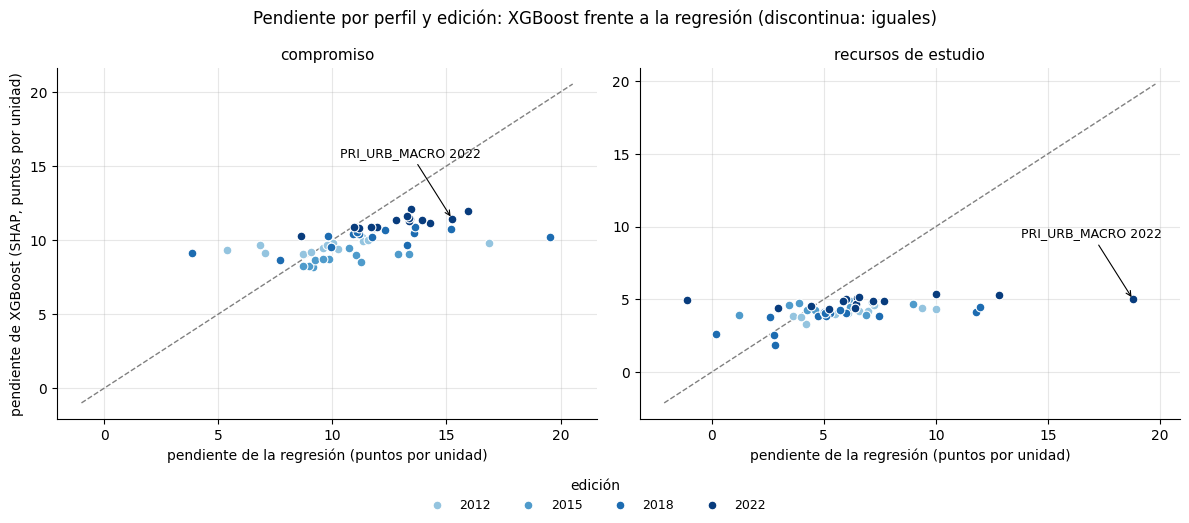

In [6]:
def pendiente_ponderada(valor, shap, peso):
    """Pendiente de la recta de mínimos cuadrados ponderados de `shap` sobre `valor`."""
    media_valor, media_shap = np.average(valor, weights=peso), np.average(shap, weights=peso)
    return np.average((valor - media_valor) * (shap - media_shap), weights=peso) / np.average((valor - media_valor) ** 2, weights=peso)


# Pendiente de SHAP sobre la variable en cada perfil-edición, junto a la de la regresión
filas = []
for variable in DE_INTERES:
    agrupado = pd.DataFrame({'year': shap_alumno['year'], 'perfil': shap_alumno['perfil'], 'valor': valores[variable], 'shap': shap_alumno[variable],
                             'peso': shap_alumno['SENWT']})
    for (edicion, perfil), grupo in agrupado.groupby(['year', 'perfil']):
        filas.append({'variable': variable, 'year': edicion, 'perfil': perfil, 'pendiente_shap': pendiente_ponderada(grupo['valor'], grupo['shap'], grupo['peso'])})
pendientes = pd.DataFrame(filas).merge(resultados_regresion[resultados_regresion['tipo'] == 'pendiente_perfil'][['variable', 'year', 'perfil', 'puntos_por_unidad', 'poco_representativo']],
                                       on=['variable', 'year', 'perfil'], validate='one_to_one')
# Correlación entre las dos pendientes, sin los perfiles poco representativos
fiables = pendientes[~pendientes['poco_representativo']]
for variable in DE_INTERES:
    de_variable = fiables[fiables['variable'] == variable]
    correlacion = np.corrcoef(de_variable['pendiente_shap'], de_variable['puntos_por_unidad'])[0, 1]
    por_edicion = de_variable.groupby('year').apply(lambda grupo: np.corrcoef(grupo['pendiente_shap'], grupo['puntos_por_unidad'])[0, 1], include_groups=False)
    print(f'{NOMBRES[variable]}: correlación entre pendientes de XGBoost y de la regresión, {len(de_variable)} perfiles-edición: {correlacion:.2f}; '
          f'por edición: {por_edicion.round(2).to_dict()}')
    print(f'  mediana del cociente XGBoost / regresión: {(de_variable["pendiente_shap"] / de_variable["puntos_por_unidad"]).median():.2f}')
revisado = pendientes[pendientes['perfil'] == 'PRI_URB_MACRO'].pivot(index='variable', columns='year', values=['pendiente_shap', 'puntos_por_unidad'])
display(Markdown('**PRI_URB_MACRO: pendiente de XGBoost y de la regresión (puntos por unidad)**'))
display(revisado.round(2))
display(Markdown('**Recursos de estudio: pendiente de XGBoost por perfil y edición (puntos por recurso)**'))
display(pendientes[pendientes['variable'] == 'recursos_estudio'].pivot(index='perfil', columns='year', values='pendiente_shap').round(2))

# Figura: pendiente de XGBoost frente a la de la regresión
fig, ejes = plt.subplots(1, 2, figsize=(12, 5.2))
for eje, variable in zip(ejes, DE_INTERES):
    de_variable = fiables[fiables['variable'] == variable]
    for edicion in EDICIONES:
        de_edicion = de_variable[de_variable['year'] == edicion]
        eje.scatter(de_edicion['puntos_por_unidad'], de_edicion['pendiente_shap'], color=COLORES_EDICION[edicion], s=40, label=str(edicion),
                    edgecolor='white', linewidth=0.8, zorder=3)
    limites = [min(de_variable['puntos_por_unidad'].min(), de_variable['pendiente_shap'].min(), 0) - 1,
               max(de_variable['puntos_por_unidad'].max(), de_variable['pendiente_shap'].max()) + 1]
    eje.plot(limites, limites, color='grey', linestyle='--', linewidth=1)
    destacado = de_variable[(de_variable['perfil'] == 'PRI_URB_MACRO') & (de_variable['year'] == 2022)].iloc[0]
    eje.annotate('PRI_URB_MACRO 2022', (destacado['puntos_por_unidad'], destacado['pendiente_shap']), textcoords='offset points', xytext=(-30, 45),
                 ha='center', fontsize=9, arrowprops={'arrowstyle': '->', 'color': 'black', 'linewidth': 0.8})
    eje.set_xlabel('pendiente de la regresión (puntos por unidad)')
    eje.set_title(NOMBRES[variable], fontsize=11)
    eje.grid(alpha=0.3)
    eje.spines[['top', 'right']].set_visible(False)
ejes[0].set_ylabel('pendiente de XGBoost (SHAP, puntos por unidad)')
fig.legend(*ejes[0].get_legend_handles_labels(), title='edición', loc='lower center', ncol=4, fontsize=9, frameon=False)
fig.suptitle('Pendiente por perfil y edición: XGBoost frente a la regresión (discontinua: iguales)', fontsize=12)
plt.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(f'{RUTA_REPORTS}/03_xgboost_pendientes_perfil.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **En el compromiso, XGBoost y la regresión ordenan los perfiles de forma parecida.** La correlación entre sus pendientes es de 0,59 en los 54 perfiles-edición fiables, y de 0,82 en 2022. XGBoost da pendientes algo más planas: la mediana del cociente es 0,90.
* **En los recursos de estudio, XGBoost da casi la misma pendiente a todos los perfiles**, entre 1,89 y 5,35 puntos por recurso, y algo mayor en 2022 (de 4,36 a 5,35) que antes. La correlación con la regresión es más baja (0,46).
* **XGBoost no reproduce el salto del privado urbano grande en 2022**: 4,99 puntos por recurso, como los demás perfiles, frente a 18,79 de la regresión.
  * El salto es propio de Australia (`03_australia_privados_grandes`) y XGBoost lo reparte entre las variables de país, perfil y recursos.
  * Con una tasa de aprendizaje baja y pocos árboles, no le compensa aislar una interacción triple que afecta a menos de 1.500 alumnos.
  * Que no lo vea no lo desmiente: un SHAP reparte entre variables y no está hecho para detectar efectos de un grupo pequeño. Pero confirma que no es un patrón general del perfil.

## 6. Guardado

Se guardan dos tablas en `models/`, con el formato de `models/README.md`:

* **`shap_alumnos.parquet`**: una fila por alumno `en_modelo`, con los identificadores (`CNT`, `year`, `CNTSCHID`, `CNTSTUID`, para unirla con `tabla_modelo_alumno.parquet`), `valor_base` (la predicción media de la edición), `prediccion` (la media de las predicciones de los modelos de los valores plausibles de su edición) y un `shap_<variable>` por variable, en puntos de matemáticas y promediado entre esos modelos. Los modelos se entrenan con todos los alumnos de la edición, ponderados con `SENWT`, y los SHAP se calculan sobre todos ellos (no solo sobre los de prueba). En cada fila, `valor_base` más la suma de los `shap_` es `prediccion`.
* **`metricas_modelos.csv`**: una fila por edición y modelo (`regresion` o `xgboost`), con el R², el RMSE y el MAE de la sección 2 (`conjunto` = `validacion_cruzada`: alumnos de prueba de los pliegues por centro, media entre valores plausibles, ponderados con `SENWT`), el número de alumnos y el de valores plausibles.

In [7]:
os.makedirs(RUTA_MODELOS, exist_ok=True)
shap_guardado = shap_alumno[['CNT', 'year', 'CNTSCHID', 'CNTSTUID', 'base', 'prediccion'] + VARIABLES].rename(
    columns={'base': 'valor_base', **{variable: f'shap_{variable}' for variable in VARIABLES}})
columnas_shap = [f'shap_{variable}' for variable in VARIABLES]
# Comprobación: valor base más SHAP reproduce la predicción
descuadre = (shap_guardado['valor_base'] + shap_guardado[columnas_shap].sum(axis=1) - shap_guardado['prediccion']).abs().max()
print(f'Mayor diferencia entre valor_base + SHAP y prediccion: {descuadre:.2e} puntos')
ruta = os.path.join(RUTA_MODELOS, 'shap_alumnos.parquet')
shap_guardado.astype({columna: 'float32' for columna in ['valor_base', 'prediccion'] + columnas_shap}).to_parquet(ruta, index=False)
print(f'{len(shap_guardado)} filas y {shap_guardado.shape[1]} columnas en {ruta}')
ruta = os.path.join(RUTA_MODELOS, 'metricas_modelos.csv')
metricas.to_csv(ruta, index=False)
print(f'{len(metricas)} filas en {ruta}')
display(metricas.round(4))

Mayor diferencia entre valor_base + SHAP y prediccion: 4.88e-04 puntos


298782 filas y 18 columnas en ../../models\shap_alumnos.parquet
8 filas en ../../models\metricas_modelos.csv


,edicion,modelo,conjunto,r2,rmse,mae,n_alumnos,valores_plausibles
0,2012,regresion,validacion_cruzada,0.3540,75.7508,60.2973,73843,5
1,2012,xgboost,validacion_cruzada,0.3852,73.8982,58.7328,73843,5
2,2015,regresion,validacion_cruzada,0.2791,77.2740,61.5119,68795,10
3,2015,xgboost,validacion_cruzada,0.3112,75.5353,60.0526,68795,10
4,2018,regresion,validacion_cruzada,0.2923,77.2077,61.2816,69878,10
5,2018,xgboost,validacion_cruzada,0.3170,75.8502,60.2060,69878,10
6,2022,regresion,validacion_cruzada,0.3117,76.1630,60.5439,86266,10
7,2022,xgboost,validacion_cruzada,0.3356,74.8298,59.4838,86266,10


## Hallazgos

* **La regresión lineal recoge casi todo lo que estas variables dicen de la nota.** XGBoost solo mejora el R² de prueba entre 0,024 y 0,032 puntos, y los árboles más profundos apenas ganan a los de dos niveles.
* **El compromiso y los recursos de estudio pesan lo mismo en las cuatro ediciones.** El compromiso mueve la predicción entre 8,6 y 10,0 puntos y los recursos, unos 3, sin tendencia. Por delante están la composición social del centro, el país y los libros en casa.
* **Los recursos de estudio tienen efecto techo.** Pasar de 3 a 5 recursos se asocia a mucha más nota que pasar de 5 a 6, y la forma no cambia entre ediciones. Una recta resume bien la tendencia, pero exagera el último recurso.
* **El índice de compromiso mezcla componentes que no pesan igual.** XGBoost ordena sus valores sobre todo por la asistencia (absentismo e impuntualidad). Los deberes, que en 2012 casi no se asociaban a la nota, sí lo hacen en 2022. Es la misma conclusión que `03_robustez_regresion`: la ligera subida del compromiso viene de los deberes.
* **No hay diferencias por perfil que la regresión no haya visto.** XGBoost da a todos los perfiles pendientes parecidas, también al privado urbano grande en 2022, cuyo salto es, en este panel, propio de Australia (`03_robustez_regresion`, sección 7).
* **Respuesta a la pregunta del TFM, con los dos modelos.**
  * La asociación del compromiso y de los recursos de estudio con la nota de matemáticas es casi la misma en 2012 y en 2022, y parecida en todos los perfiles de centro.
  * El cambio más claro es que el tiempo de deberes adecuado se asocia a más nota en 2022, aunque esa comparación está limitada por cómo se mide.
  * En este panel de 12 países, la única diferencia entre perfiles, la de los privados urbanos grandes en 2022, es un fenómeno de Australia. En el panel ampliado de 25 países hay diferencias entre perfiles en 2022 que no dependen de un país (`03_robustez_regresion`, sección 7).

Es el último notebook de la línea principal. El orden completo está en `00_pipeline_multiedicion_PISA` («Orden de los notebooks»).